# N-CMAPSS DS02-006：数据机制、参数与校准准备

**组会讲解版 · 使用本地真实 HDF5 运行 · 只研究 DS02-006。**

这份 notebook 先回答“数据是什么、观测到的变化来自哪里、怎样为健康参数反演做准备”。不训练 RUL 模型，不把探索性相关性当作机理验证，不把测试发动机的描述统计用来选择模型。

**建议讲解顺序（约 15–20 分钟）**：生成机制 → 文件/参数字典 → 发动机与循环 → 单次飞行 → RUL 时间尺度 → 健康轨迹 → 工况差异 → 校准前提。

本文件中三个标记的含义：**[论文]** 为原始文献中的定义；**[实测]** 为当前 H5 文件计算得到的结果；**[建议]** 为后续研究设计，不是已经证明的结论。

主要文献：Arias Chao, M., Kulkarni, C., Goebel, K., & Fink, O. (2021). *Aircraft Engine Run-to-Failure Dataset under Real Flight Conditions for Prognostics and Diagnostics*. Data, 6(1), 5. [DOI](https://doi.org/10.3390/data6010005)。对照其 Fig. 1、Eq. (1)、Tables 3–8、Sections 3.1–3.3 阅读。

**重要修正**：不能把数据生成理解成“先生成传感器值，再统一乘一条健康曲线”。健康参数作用于发动机部件性能模型，改变整个耦合系统的响应。

In [1]:
# 0. 环境与路径。可直接从上到下运行；不修改原始数据。
from pathlib import Path
import json, time, platform, hashlib
import h5py
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown

DATA_PATH = Path(r'E:\RUL\N-CMAPSS_DS02-006.h5')
ARTIFACT_DIR = Path.cwd() / 'DS02_analysis_assets'
ARTIFACT_DIR.mkdir(exist_ok=True)
assert DATA_PATH.is_file(), f'请修改 DATA_PATH：{DATA_PATH}'
FS_HZ = 1.0  # [论文] 原始数据采样率；H5 没有单独时间戳，此处不是从文件推断
SAMPLES_PER_CYCLE = 32  # 只影响散点/相关性近似；计数、均值、范围均扫描全量
TRAIN_UNITS = [2, 5, 10, 16, 18]
VAL_UNIT = 20
COLORS = {'dev': '#29699A', 'test': '#D5783E'}
font_names = {f.name for f in font_manager.fontManager.ttflist}
cn_font = next((x for x in ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'SimSun'] if x in font_names), 'DejaVu Sans')
plt.rcParams.update({'font.family': cn_font, 'axes.unicode_minus': False,
                     'figure.dpi': 110, 'savefig.dpi': 160, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 70)
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 150)

def show(fig, name, caption):
    # PNG 方便后续粘贴 PPT；notebook 同时嵌入图片，不依赖外部图文件查看。
    fig.savefig(ARTIFACT_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()
    display(Markdown('**读图：** '+caption))

def names_of(f, key):
    return [x.decode() if isinstance(x, bytes) else str(x) for x in f[key][:]]

display(Markdown(f'数据：`{DATA_PATH.name}`；大小 **{DATA_PATH.stat().st_size/2**30:.2f} GiB**；中文字体：{cn_font}。'))

数据：`N-CMAPSS_DS02-006.h5`；大小 **2.28 GiB**；中文字体：Microsoft YaHei。

## 1. 生成机制：真实飞行工况驱动的发动机退化仿真

**[论文，Fig. 1 / Eq. 1]** 用真实飞行记录描述工况 (W)，为部件施加健康参数 (	heta) 的演化，再通过 CMAPSS 耦合模型计算传感器响应。简写为：

\[
[X_s(t),X_v(t)] = F\bigl(W(t),\theta(t)\bigr),\qquad
X_s^{obs}(t)=X_s(t)+\epsilon_t.
\]

- `W` 是真实飞行场景描述；`X_s` 是仿真的**可观测传感器通道**，并非该发动机真实故障飞行的直接测量。
- `X_v` 是模型内部的虚拟量；“仿真得到的 X_s”与“名为 X_v 的虚拟传感器组”不能混淆。
- 健康变化包含初始磨损、正常退化和异常退化阶段，不能预设所有发动机初始状态相同。
- [论文 §3.3] `X_s` 加入目标 SNR 为 65 dB 的高斯噪声；`W` 的真实飞行记录自身含噪声。**65 dB 不能直接当作粒子滤波的标准差。**

**讲解提示**：“真实的是飞行条件，退化发动机的响应是仿真的；校准要做的是在给定工况下反解内部健康状态。”

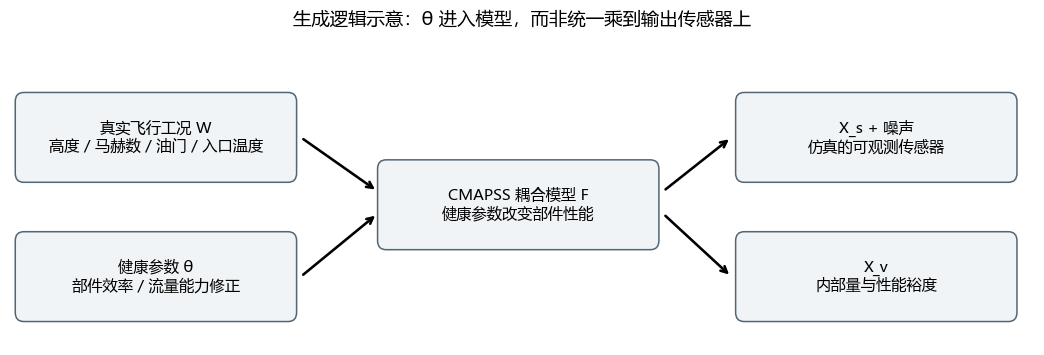

**读图：** 示意图依据原始论文 Fig. 1 / Eq. (1) 重新绘制，未代表某一实测数值。

In [2]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.set(xlim=(0, 12), ylim=(0, 3.3)); ax.axis('off')
nodes = [(0.15, 1.9, '真实飞行工况 W\n高度 / 马赫数 / 油门 / 入口温度'),
         (0.15, .35, '健康参数 θ\n部件效率 / 流量能力修正'),
         (4.4, 1.15, 'CMAPSS 耦合模型 F\n健康参数改变部件性能'),
         (8.6, 1.9, 'X_s + 噪声\n仿真的可观测传感器'),
         (8.6, .35, 'X_v\n内部量与性能裕度')]
for x, y, text in nodes:
    ax.add_patch(FancyBboxPatch((x,y),3.1,.8,boxstyle='round,pad=.1',facecolor='#F1F4F6',edgecolor='#536675'))
    ax.text(x+1.55,y+.4,text,ha='center',va='center',fontsize=10)
for start, end in [((3.4,2.3),(4.3,1.7)),((3.4,.75),(4.3,1.45)),((7.65,1.7),(8.45,2.3)),((7.65,1.45),(8.45,.75))]:
    ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','lw':1.7})
ax.set_title('生成逻辑示意：θ 进入模型，而非统一乘到输出传感器上',pad=15)
show(fig,'01_generation','示意图依据原始论文 Fig. 1 / Eq. (1) 重新绘制，未代表某一实测数值。')

## 2. HDF5 文件中到底有什么？

`_dev` 是开发集，仍需在内部划分训练/验证；`_test` 是独立发动机测试集；`_var` 保存列名。所有二维数组的同一行必须对齐，切分时不能分别打乱。

以下形状和列名直接读取当前文件。本文不把其他 N-CMAPSS 子集的发动机数量套用到 DS02。

In [3]:
GROUPS = {'W':'W_var', 'X_s':'X_s_var', 'X_v':'X_v_var', 'T':'T_var', 'A':'A_var'}
with h5py.File(DATA_PATH, 'r') as f:
    NAMES = {g:names_of(f,v) for g,v in GROUPS.items()}
    inventory = pd.DataFrame([{'H5键':k,'形状':str(f[k].shape),'dtype':str(f[k].dtype),
                               '未压缩MiB':f[k].size*f[k].dtype.itemsize/2**20} for k in f])
    row_counts = {s:len(f[f'Y_{s}']) for s in ['dev','test']}
    for s in row_counts:
        assert all(len(f[f'{g}_{s}']) == row_counts[s] for g in GROUPS), '数组行未对齐'
display(inventory)
display(Markdown('**当前文件列顺序**（应按名称定位，不假设论文表格的展示顺序等于存储顺序）：'))
for g,n in NAMES.items():
    print(g, n)
inventory.to_csv(ARTIFACT_DIR/'h5_inventory.csv',index=False,encoding='utf-8-sig')

,H5键,形状,dtype,未压缩MiB
0,A_dev,"(5263447, 4)",float64,160.627655
1,A_test,"(1253743, 4)",float64,38.261200
2,A_var,"(4,)",|S5,0.000019
3,T_dev,"(5263447, 10)",float64,401.569138
4,T_test,"(1253743, 10)",float64,95.653000
5,T_var,"(10,)",|S12,0.000114
6,W_dev,"(5263447, 4)",float64,160.627655
7,W_test,"(1253743, 4)",float64,38.261200
8,W_var,"(4,)",|S4,0.000015
9,X_s_dev,"(5263447, 14)",float64,562.196793


**当前文件列顺序**（应按名称定位，不假设论文表格的展示顺序等于存储顺序）：

W ['alt', 'Mach', 'TRA', 'T2']
X_s ['T24', 'T30', 'T48', 'T50', 'P15', 'P2', 'P21', 'P24', 'Ps30', 'P40', 'P50', 'Nf', 'Nc', 'Wf']
X_v ['T40', 'P30', 'P45', 'W21', 'W22', 'W25', 'W31', 'W32', 'W48', 'W50', 'SmFan', 'SmLPC', 'SmHPC', 'phi']
T ['fan_eff_mod', 'fan_flow_mod', 'LPC_eff_mod', 'LPC_flow_mod', 'HPC_eff_mod', 'HPC_flow_mod', 'HPT_eff_mod', 'HPT_flow_mod', 'LPT_eff_mod', 'LPT_flow_mod']
A ['unit', 'cycle', 'Fc', 'hs']


## 3. 参数字典与“能不能作为模型输入”

下表的符号/单位对照原始论文 Tables 4–8，存储顺序以当前文件为准。用途列是本研究建议。

**注意单位**：`°R` 是兰氏绝对温标，不是摄氏度；`psia` 是绝对压力；`pps` 即 lb/s。健康参数的 `mod` 是无量纲修正量，不能直接解释成“剩余健康百分比”。

In [4]:
DESCRIPTIONS = {
'alt':('高度','ft'),'Mach':('马赫数','无量纲'),'TRA':('油门杆角度','%'),'T2':('风扇入口总温','°R'),
'T24':('低压压气机出口总温','°R'),'T30':('高压压气机出口总温','°R'),
'T48':('高压涡轮出口总温','°R'),'T50':('低压涡轮出口总温','°R'),
'P15':('外涵道总压','psia'),'P2':('风扇入口总压','psia'),'P21':('风扇出口总压','psia'),
'P24':('低压压气机出口总压','psia'),'Ps30':('高压压气机出口静压','psia'),
'P40':('燃烧室出口总压','psia'),'P50':('低压涡轮出口总压','psia'),
'Nf':('风扇转速','rpm'),'Nc':('核心机转速','rpm'),'Wf':('燃油流量','lb/s'),
'T40':('燃烧室出口总温','°R'),'P30':('高压压气机出口总压','psia'),
'P45':('高压涡轮出口总压','psia'),'W21':('风扇流量','lb/s'),
'W22':('低压压气机出口流量','lb/s'),'W25':('高压压气机入口流量','lb/s'),
'W31':('高压涡轮冷却引气流量','lb/s'),'W32':('高压涡轮冷却引气流量','lb/s'),
'W48':('高压涡轮出口流量','lb/s'),'W50':('低压涡轮出口流量','lb/s'),
'SmFan':('风扇失速裕度','无量纲'),'SmLPC':('低压压气机失速裕度','无量纲'),
'SmHPC':('高压压气机失速裕度','无量纲'),'phi':('燃油流量与 Ps30 之比','lb/(s·psi)'),
'unit':('发动机编号','编号'),'cycle':('飞行循环编号','cycle'),
'Fc':('飞行类别：短 / 中 / 长','类别1/2/3'),'hs':('健康/异常阶段标记','二值标记'),
'Y':('到轨迹寿命终点的剩余循环数','cycle')}
components={'fan':'风扇','LPC':'低压压气机','HPC':'高压压气机','HPT':'高压涡轮','LPT':'低压涡轮'}
for n in NAMES['T']:
    component = n.split('_')[0]
    DESCRIPTIONS[n]=(components[component]+('效率修正量' if '_eff_' in n else '流量能力修正量'),'无量纲')
roles={'W':'常规输入：描述工况','X_s':'常规输入：可观测通道',
       'X_v':'隐藏仿真量：诊断参考 / 特权信息实验',
       'T':'校准真值：训练监督、评估、oracle；实际反演不能读取目标真值',
       'A':'索引/分组；hs 不用于目标在线输入','Y':'监督标签；目标适应阶段不可读取'}
dictionary=[]
for g, variables in {**NAMES,'Y':['Y']}.items():
    for i,n in enumerate(variables):
        desc,unit=DESCRIPTIONS.get(n,('请查原文','待核实'))
        dictionary.append({'组':g,'列号(0起)':i,'变量':n,'含义':desc,'单位':unit,'研究用途':roles[g]})
dictionary=pd.DataFrame(dictionary)
for g in ['W','X_s','X_v','T','A','Y']:
    display(Markdown(f'**{g}**'))
    display(dictionary[dictionary['组']==g].reset_index(drop=True))
dictionary.to_csv(ARTIFACT_DIR/'variable_dictionary.csv',index=False,encoding='utf-8-sig')
display(Markdown('**口径说明：** 原文 Table 7 的 LPT_flow_mod 描述出现 HPT 字样；本字典按变量名解释为 LPT 流量修正量。W32 的具体冷却流路在建物理方程前仍应核对 CMAPSS 模型文档，不能只凭缩写推断。'))

**W**

,组,列号(0起),变量,含义,单位,研究用途
0,W,0,alt,高度,ft,常规输入：描述工况
1,W,1,Mach,马赫数,无量纲,常规输入：描述工况
2,W,2,TRA,油门杆角度,%,常规输入：描述工况
3,W,3,T2,风扇入口总温,°R,常规输入：描述工况


**X_s**

,组,列号(0起),变量,含义,单位,研究用途
0,X_s,0,T24,低压压气机出口总温,°R,常规输入：可观测通道
1,X_s,1,T30,高压压气机出口总温,°R,常规输入：可观测通道
2,X_s,2,T48,高压涡轮出口总温,°R,常规输入：可观测通道
3,X_s,3,T50,低压涡轮出口总温,°R,常规输入：可观测通道
4,X_s,4,P15,外涵道总压,psia,常规输入：可观测通道
5,X_s,5,P2,风扇入口总压,psia,常规输入：可观测通道
6,X_s,6,P21,风扇出口总压,psia,常规输入：可观测通道
7,X_s,7,P24,低压压气机出口总压,psia,常规输入：可观测通道
8,X_s,8,Ps30,高压压气机出口静压,psia,常规输入：可观测通道
9,X_s,9,P40,燃烧室出口总压,psia,常规输入：可观测通道


**X_v**

,组,列号(0起),变量,含义,单位,研究用途
0,X_v,0,T40,燃烧室出口总温,°R,隐藏仿真量：诊断参考 / 特权信息实验
1,X_v,1,P30,高压压气机出口总压,psia,隐藏仿真量：诊断参考 / 特权信息实验
2,X_v,2,P45,高压涡轮出口总压,psia,隐藏仿真量：诊断参考 / 特权信息实验
3,X_v,3,W21,风扇流量,lb/s,隐藏仿真量：诊断参考 / 特权信息实验
4,X_v,4,W22,低压压气机出口流量,lb/s,隐藏仿真量：诊断参考 / 特权信息实验
5,X_v,5,W25,高压压气机入口流量,lb/s,隐藏仿真量：诊断参考 / 特权信息实验
6,X_v,6,W31,高压涡轮冷却引气流量,lb/s,隐藏仿真量：诊断参考 / 特权信息实验
7,X_v,7,W32,高压涡轮冷却引气流量,lb/s,隐藏仿真量：诊断参考 / 特权信息实验
8,X_v,8,W48,高压涡轮出口流量,lb/s,隐藏仿真量：诊断参考 / 特权信息实验
9,X_v,9,W50,低压涡轮出口流量,lb/s,隐藏仿真量：诊断参考 / 特权信息实验


... (3 outputs left out)

,组,列号(0起),变量,含义,单位,研究用途
0,A,0,unit,发动机编号,编号,索引/分组；hs 不用于目标在线输入
1,A,1,cycle,飞行循环编号,cycle,索引/分组；hs 不用于目标在线输入
2,A,2,Fc,飞行类别：短 / 中 / 长,类别1/2/3,索引/分组；hs 不用于目标在线输入
3,A,3,hs,健康/异常阶段标记,二值标记,索引/分组；hs 不用于目标在线输入


**Y**

,组,列号(0起),变量,含义,单位,研究用途
0,Y,0,Y,到轨迹寿命终点的剩余循环数,cycle,监督标签；目标适应阶段不可读取


**口径说明：** 原文 Table 7 的 LPT_flow_mod 描述出现 HPT 字样；本字典按变量名解释为 LPT 流量修正量。W32 的具体冷却流路在建物理方程前仍应核对 CMAPSS 模型文档，不能只凭缩写推断。

## 4. 全量扫描：发动机 → 飞行循环 → 秒级采样点

每次只读取一段飞行循环，避免把所有传感器一次性载入内存。

- **精确统计**：行数、每循环均值、最小/最大值、缺失值、RUL 一致性、健康参数循环内范围。
- **近似统计**：每循环均匀抽取 32 点用于散点图/相关性；不是全量相关性估计，也不是训练数据预处理。
- `记录时长` 按原始 1 Hz 换算，表示文件保存片段的时长，不保证是机场起降间的完整航班时长。

测试集仅用于这里的数据描述；下文示范的工况回归只在指定训练发动机拟合，在 Unit20 上诊断。

In [5]:
t0=time.perf_counter()
cycle_rows=[]; sampled=[]; exact_ranges=[]
for split in ['dev','test']:
    with h5py.File(DATA_PATH,'r') as f:
        # A 四列较小，用于定位连续的发动机/飞行循环边界。
        a=f[f'A_{split}'][:]
        starts=np.r_[0,np.flatnonzero(np.any(a[1:,:2]!=a[:-1,:2],axis=1))+1]
        ends=np.r_[starts[1:],len(a)]
        trackers={g:{'min':np.full(len(NAMES[g]),np.inf), 'max':np.full(len(NAMES[g]),-np.inf),
                     'missing':np.zeros(len(NAMES[g]),dtype=np.int64)} for g in ['W','X_s','X_v','T']}
        for k,(s,e) in enumerate(zip(starts,ends)):
            raw={g:f[f'{g}_{split}'][s:e].astype(np.float64) for g in trackers}
            y=f[f'Y_{split}'][s:e].reshape(-1)
            unit,cycle,fc=a[s,:3].astype(int)
            rec={'split':split,'unit':unit,'cycle':cycle,'Fc':fc,'n_rows':int(e-s),
                 'start_row':int(s),'end_row':int(e), 'recorded_hours':(e-s)/FS_HZ/3600,
                 'RUL_min':float(np.min(y)), 'RUL_max':float(np.max(y)),
                 'RUL':float(np.mean(y)), 'hs':float(np.mean(a[s:e,3])),
                 'A_missing':int(np.sum(~np.isfinite(a[s:e]))),'Y_missing':int(np.sum(~np.isfinite(y)))}
            for g,arr in raw.items():
                trackers[g]['min']=np.minimum(trackers[g]['min'],np.nanmin(arr,axis=0))
                trackers[g]['max']=np.maximum(trackers[g]['max'],np.nanmax(arr,axis=0))
                trackers[g]['missing']+=np.sum(~np.isfinite(arr),axis=0)
                for j,n in enumerate(NAMES[g]):
                    rec[n]=float(np.mean(arr[:,j]))
                    if g=='T': rec[n+'_within_range']=float(np.ptp(arr[:,j]))
            # 全量检查一个候选冗余关系，仅描述当前文件，不预设普适物理定律。
            ratio=raw['X_s'][:,NAMES['X_s'].index('P15')]/raw['X_s'][:,NAMES['X_s'].index('P21')]
            rec['P15_P21_ratio_min']=float(ratio.min())
            rec['P15_P21_ratio_max']=float(ratio.max())
            # 相邻点高度变化识别阶段，循环首点不跨前一航班做差分。
            delta=np.diff(raw['W'][:,NAMES['W'].index('alt')])*FS_HZ
            phase=np.full(e-s,1,dtype=int)
            phase[1:]=np.where(delta>=.5,0,np.where(delta<=-.5,2,1))
            for p in range(3): rec[f'phase_{p}_fraction']=float(np.mean(phase[1:]==p))
            cycle_rows.append(rec)
            ids=np.unique(np.linspace(0,e-s-1,SAMPLES_PER_CYCLE).astype(int))
            frame=pd.DataFrame(np.concatenate(list(raw.values()),axis=1),
                               columns=sum([NAMES[g] for g in raw],[])).iloc[ids].copy()
            frame['split']=split; frame['unit']=unit; frame['cycle']=cycle; frame['Fc']=fc
            frame['RUL']=y[ids]; frame['hs']=a[s:e,3][ids]; frame['phase']=phase[ids]
            frame['row']=s+ids
            sampled.append(frame)
        for g,st in trackers.items():
            for j,n in enumerate(NAMES[g]):
                exact_ranges.append({'split':split,'group':g,'variable':n,'min':st['min'][j],
                                     'max':st['max'][j],'range':st['max'][j]-st['min'][j],
                                     'nonfinite':int(st['missing'][j])})
        print(f'{split}: {len(a):,} 行；{len(starts)} 个连续飞行循环块；{len(np.unique(a[:,0]))} 台发动机')
        del a
cycles=pd.DataFrame(cycle_rows)
samples=pd.concat(sampled,ignore_index=True)
ranges=pd.DataFrame(exact_ranges)
assert not cycles.duplicated(['split','unit','cycle']).any(), '同一个循环被拆成不连续块，需检查文件排序'
assert cycles['n_rows'].sum()==sum(row_counts.values())
cycles.to_csv(ARTIFACT_DIR/'cycle_summary.csv',index=False,encoding='utf-8-sig')
ranges.to_csv(ARTIFACT_DIR/'exact_variable_ranges.csv',index=False,encoding='utf-8-sig')
display(Markdown(f'扫描完成：**{len(cycles):,} 个循环，{len(samples):,} 个展示抽样点**；耗时 {time.perf_counter()-t0:.1f} 秒。'))

dev: 5,263,447 行；446 个连续飞行循环块；6 台发动机


test: 1,253,743 行；202 个连续飞行循环块；3 台发动机


扫描完成：**648 个循环，20,736 个展示抽样点**；耗时 9.2 秒。

,split,unit,Fc,cycles,first_cycle,last_cycle,rows,mean_recorded_hours,RUL_first,RUL_last,proposed_role
0,dev,2,3,75,1,75,853142,3.159785,74.0,0.0,训练
1,dev,5,3,89,1,89,1033420,3.225406,88.0,0.0,训练
2,dev,10,3,82,1,82,952711,3.227341,81.0,0.0,训练
3,dev,16,3,63,1,63,765295,3.374317,62.0,0.0,训练
4,dev,18,3,71,1,71,890719,3.484816,70.0,0.0,训练
5,dev,20,3,66,1,66,768160,3.232997,65.0,0.0,验证
6,test,11,3,59,1,59,663495,3.123799,58.0,0.0,描述/最终测试
7,test,14,1,76,1,76,156778,0.573019,75.0,0.0,描述/最终测试
8,test,15,2,67,1,67,433470,1.797139,66.0,0.0,描述/最终测试


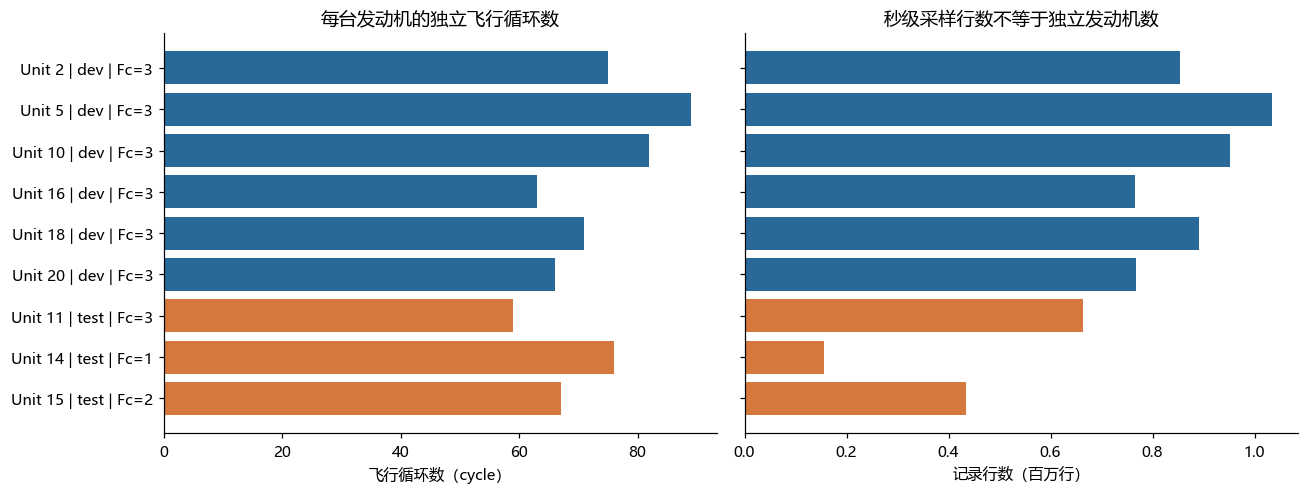

**读图：** 来源：当前 H5 全量 A/Y。开发集蓝色、测试集橙色。应先按发动机划分，再构造窗口；海量重叠窗口不能替代独立发动机样本。

In [6]:
units=(cycles.groupby(['split','unit','Fc'],as_index=False)
       .agg(cycles=('cycle','nunique'),first_cycle=('cycle','min'),last_cycle=('cycle','max'),
            rows=('n_rows','sum'),mean_recorded_hours=('recorded_hours','mean'),
            RUL_first=('RUL','max'),RUL_last=('RUL','min')))
units['proposed_role']=np.where(units['split']=='test','描述/最终测试',
                              np.where(units['unit']==VAL_UNIT,'验证','训练'))
display(units)
units.to_csv(ARTIFACT_DIR/'engine_summary.csv',index=False,encoding='utf-8-sig')
fig,axs=plt.subplots(1,2,figsize=(12,4.6),sharey=True)
labels=[f"Unit {u} | {s} | Fc={fc}" for s,u,fc in zip(units.split,units.unit,units.Fc)]
yy=np.arange(len(units)); color=[COLORS[s] for s in units.split]
axs[0].barh(yy,units.cycles,color=color); axs[0].set_yticks(yy,labels); axs[0].invert_yaxis()
axs[0].set(xlabel='飞行循环数（cycle）',title='每台发动机的独立飞行循环数')
axs[1].barh(yy,units.rows/1e6,color=color)
axs[1].set(xlabel='记录行数（百万行）',title='秒级采样行数不等于独立发动机数')
fig.tight_layout()
show(fig,'02_engines','来源：当前 H5 全量 A/Y。开发集蓝色、测试集橙色。应先按发动机划分，再构造窗口；海量重叠窗口不能替代独立发动机样本。')

## 5. 一次飞行中：工况变化很快，健康状态可能变化很慢

以下选择开发集 Unit 5 的一个中间循环。所有折线均来自这个真实文件片段；横轴是该记录片段开始后的分钟数，并非发动机总寿命。

上升/平飞/下降由**向后差分**的高度变化率划分，阈值 ±0.5 ft/s 参考 Nejjar 等的工况对齐论文；这只是后续方法的可解释起点，不是原文件提供的真值阶段标签。Fc 则是发动机所属的飞行类别，两者不是同一变量。

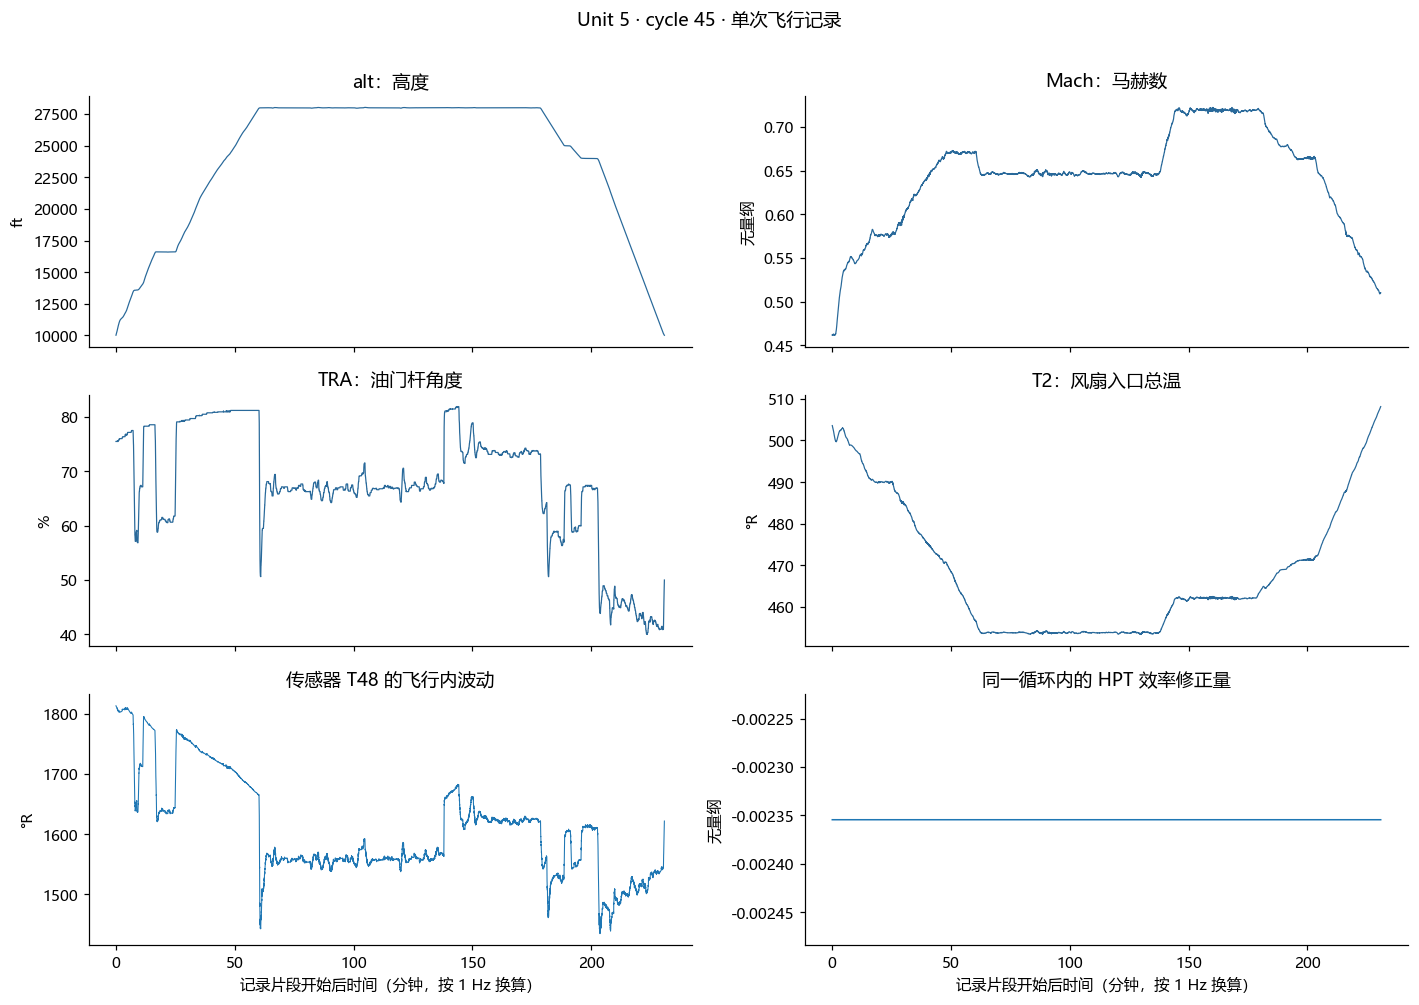

**读图：** 来源：开发集单个循环全量原始点。比较传感器波动与 θ 波动的尺度；不能把温度的每次上升都解释成新增损伤。

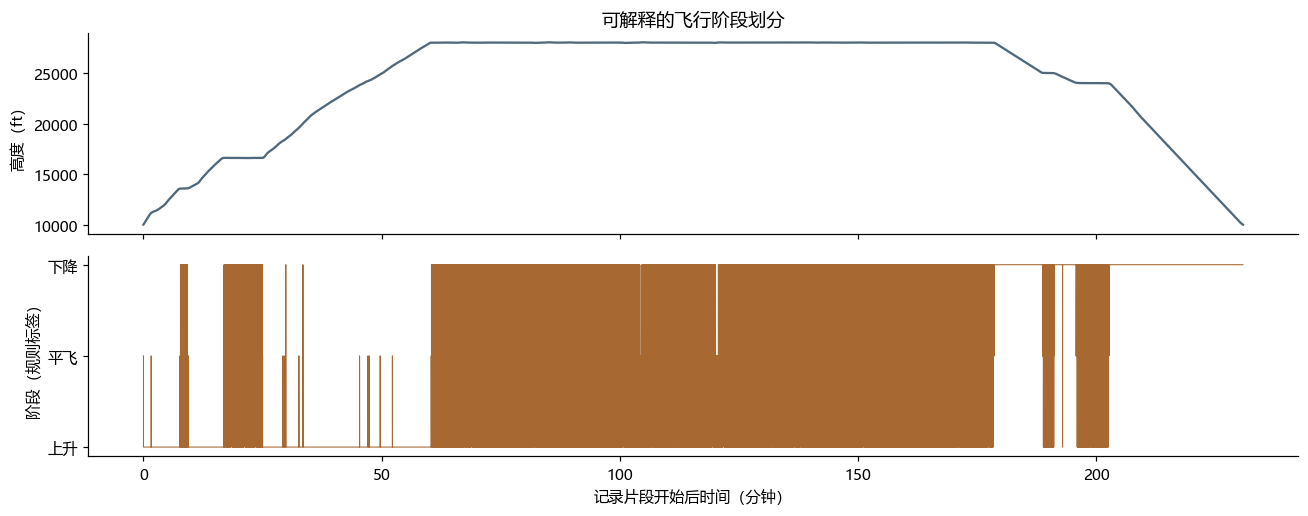

**读图：** 来源：单次飞行高度向后差分，±0.5 ft/s；没有跨循环计算高度差。边界可能抖动，后续可研究因果平滑或软分配，不能使用未来数据平滑在线输入。

In [7]:
example=cycles[(cycles.split=='dev') & (cycles.unit==5)].iloc[len(cycles[cycles.unit==5])//2]
with h5py.File(DATA_PATH,'r') as f:
    s,e=int(example.start_row),int(example.end_row)
    flight={g:f[f'{g}_dev'][s:e] for g in ['W','X_s','T','A','Y']}
minutes=np.arange(e-s)/FS_HZ/60
alt=flight['W'][:,NAMES['W'].index('alt')]
vertical=np.r_[np.nan,np.diff(alt)*FS_HZ]
phase=np.where(vertical>=.5,0,np.where(vertical<=-.5,2,1))
fig,axs=plt.subplots(3,2,figsize=(13,9),sharex=True)
for ax,var in zip(axs.flat[:4],['alt','Mach','TRA','T2']):
    ax.plot(minutes,flight['W'][:,NAMES['W'].index(var)],lw=.8,color=COLORS['dev'])
    ax.set(title=f'{var}：{DESCRIPTIONS[var][0]}',ylabel=DESCRIPTIONS[var][1])
axs[2,0].plot(minutes,flight['X_s'][:,NAMES['X_s'].index('T48')],lw=.7)
axs[2,0].set(title='传感器 T48 的飞行内波动',ylabel='°R')
axs[2,1].plot(minutes,flight['T'][:,NAMES['T'].index('HPT_eff_mod')],lw=1)
axs[2,1].set(title='同一循环内的 HPT 效率修正量',ylabel='无量纲')
for ax in axs[-1]: ax.set_xlabel('记录片段开始后时间（分钟，按 1 Hz 换算）')
fig.suptitle(f'Unit 5 · cycle {int(example.cycle)} · 单次飞行记录',y=1.01)
fig.tight_layout()
show(fig,'03_one_flight','来源：开发集单个循环全量原始点。比较传感器波动与 θ 波动的尺度；不能把温度的每次上升都解释成新增损伤。')
fig,axs=plt.subplots(2,1,figsize=(12,4.8),sharex=True)
axs[0].plot(minutes,alt,color='#4F687C'); axs[0].set(ylabel='高度（ft）',title='可解释的飞行阶段划分')
axs[1].step(minutes,phase,where='post',color='#A76832',lw=.7)
axs[1].set(yticks=[0,1,2],yticklabels=['上升','平飞','下降'],xlabel='记录片段开始后时间（分钟）',ylabel='阶段（规则标签）')
fig.tight_layout()
show(fig,'04_flight_phase','来源：单次飞行高度向后差分，±0.5 ft/s；没有跨循环计算高度差。边界可能抖动，后续可研究因果平滑或软分配，不能使用未来数据平滑在线输入。')

## 6. 时间尺度：50 个采样点不是 50 次飞行；RUL 的单位是循环

校验两件事：①同一次飞行内 `Y` 是否相同；②同一发动机上 `Y + cycle` 是否为常数。

只有第二个关系成立、且未对 RUL 截顶时，才可使用自监督关系

\[
\widehat{RUL}_{u,c_a}-\widehat{RUL}_{u,c_b}\approx c_b-c_a.
\]

这与“两个随机 batch 样本的预测应当递减”完全不同。秒级记录索引不能直接代替循环差。

,split,unit,max_RUL_range_in_cycle,range_RUL_plus_cycle,inferred_end_cycle,last_RUL
0,dev,2,0.0,0.0,75.0,0.0
1,dev,5,0.0,0.0,89.0,0.0
2,dev,10,0.0,0.0,82.0,0.0
3,dev,16,0.0,0.0,63.0,0.0
4,dev,18,0.0,0.0,71.0,0.0
5,dev,20,0.0,0.0,66.0,0.0
6,test,11,0.0,0.0,59.0,0.0
7,test,14,0.0,0.0,76.0,0.0
8,test,15,0.0,0.0,67.0,0.0


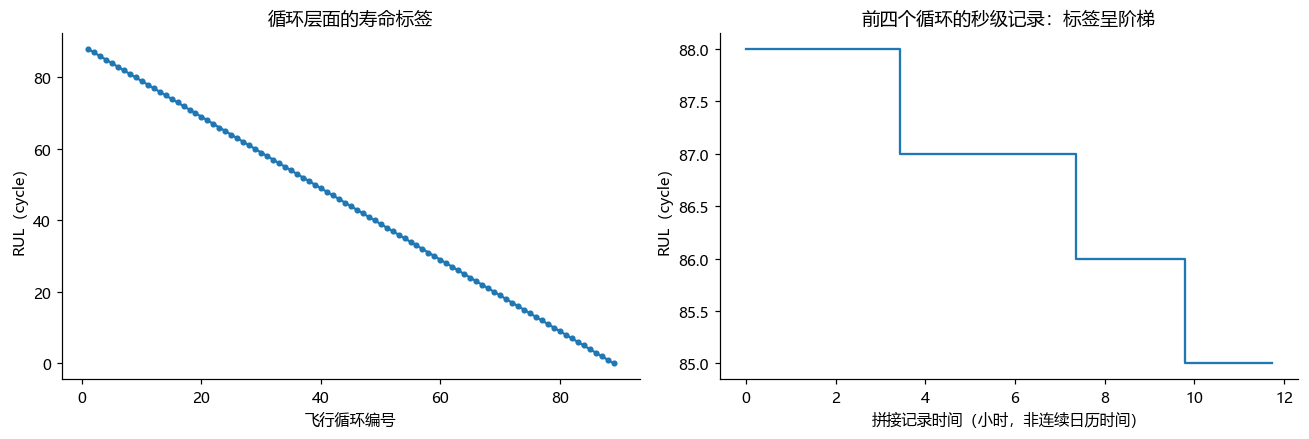

**读图：** 来源：全量循环级标签审计；右图使用每循环 32 个展示点。50 点窗口在 1 Hz 下包含 50 个观测、首末点相隔 49 秒，不代表 50 个 cycle。

In [8]:
label_audit=[]
for (split,u),g in cycles.groupby(['split','unit']):
    total=g.RUL+g.cycle
    label_audit.append({'split':split,'unit':u,'max_RUL_range_in_cycle':float((g.RUL_max-g.RUL_min).max()),
                        'range_RUL_plus_cycle':float(total.max()-total.min()),
                        'inferred_end_cycle':float(total.mean()),'last_RUL':float(g.RUL.iloc[-1])})
label_audit=pd.DataFrame(label_audit)
display(label_audit)
u=5; g=cycles[(cycles.split=='dev') & (cycles.unit==u)].sort_values('cycle')
sp=samples[(samples.split=='dev') & (samples.unit==u)].sort_values('row')
fig,axs=plt.subplots(1,2,figsize=(12,4.1))
axs[0].plot(g.cycle,g.RUL,'o-',ms=3); axs[0].set(xlabel='飞行循环编号',ylabel='RUL（cycle）',title='循环层面的寿命标签')
first=sp[sp.cycle.isin(g.cycle.iloc[:4])]
axs[1].step((first.row-first.row.iloc[0])/FS_HZ/3600,first.RUL,where='post')
axs[1].set(xlabel='拼接记录时间（小时，非连续日历时间）',ylabel='RUL（cycle）',title='前四个循环的秒级记录：标签呈阶梯')
fig.tight_layout()
show(fig,'05_rul_time_scale','来源：全量循环级标签审计；右图使用每循环 32 个展示点。50 点窗口在 1 Hz 下包含 50 个观测、首末点相隔 49 秒，不代表 50 个 cycle。')

## 7. 健康参数：哪些通道真的变化？哪些只是常数？

下图先做全量范围检查，再展示逐循环平均轨迹。这里读取 `T_test` 是为了数据集讲解与事后分析；后续部署模型不能把它当作可观测输入。

**[建议]** 只在训练发动机中识别待估计维度；如果测试时出现训练中未变化的故障通道，要把它当作超出训练支持范围的问题，不能事后修改维度再宣称纯盲测。

**训练发动机中变化的健康通道：** `HPT_eff_mod`, `LPT_eff_mod`, `LPT_flow_mod`

,split,group,variable,min,max,range,nonfinite
0,dev,T,fan_eff_mod,0.000000,0.000000,0.000000,0
1,dev,T,fan_flow_mod,0.000000,0.000000,0.000000,0
2,dev,T,LPC_eff_mod,0.000000,0.000000,0.000000,0
3,dev,T,LPC_flow_mod,0.000000,0.000000,0.000000,0
4,dev,T,HPC_eff_mod,0.000000,0.000000,0.000000,0
5,dev,T,HPC_flow_mod,0.000000,0.000000,0.000000,0
6,dev,T,HPT_eff_mod,-0.018668,0.000021,0.018690,0
7,dev,T,HPT_flow_mod,0.000000,0.000000,0.000000,0
8,dev,T,LPT_eff_mod,-0.023184,0.000075,0.023258,0
9,dev,T,LPT_flow_mod,-0.017672,0.000000,0.017672,0


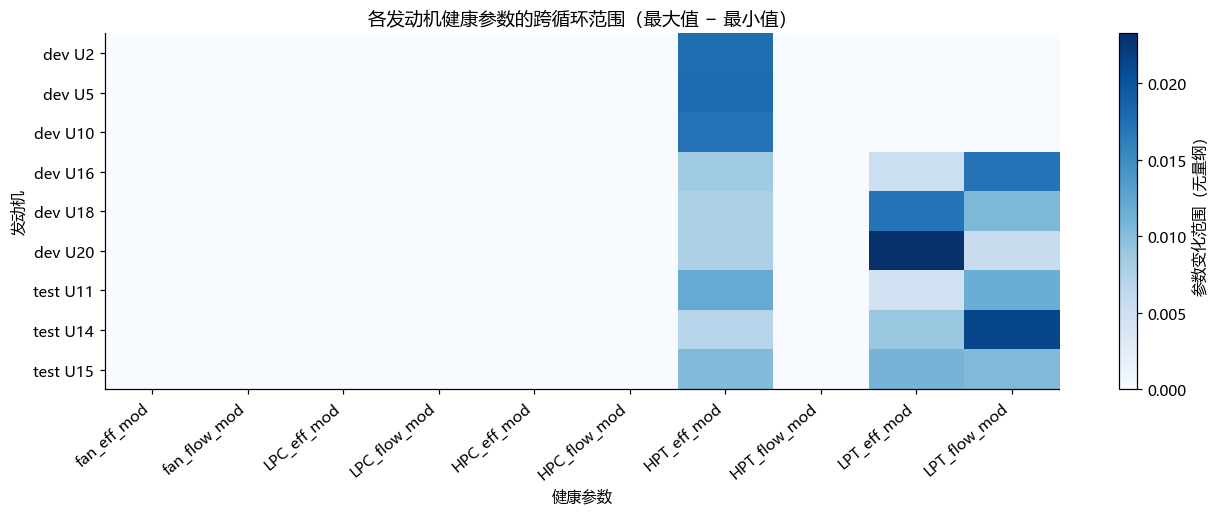

**读图：** 来源：全量循环均值。零范围表示该发动机该通道没有随循环变化，不表示发动机整体没有退化。

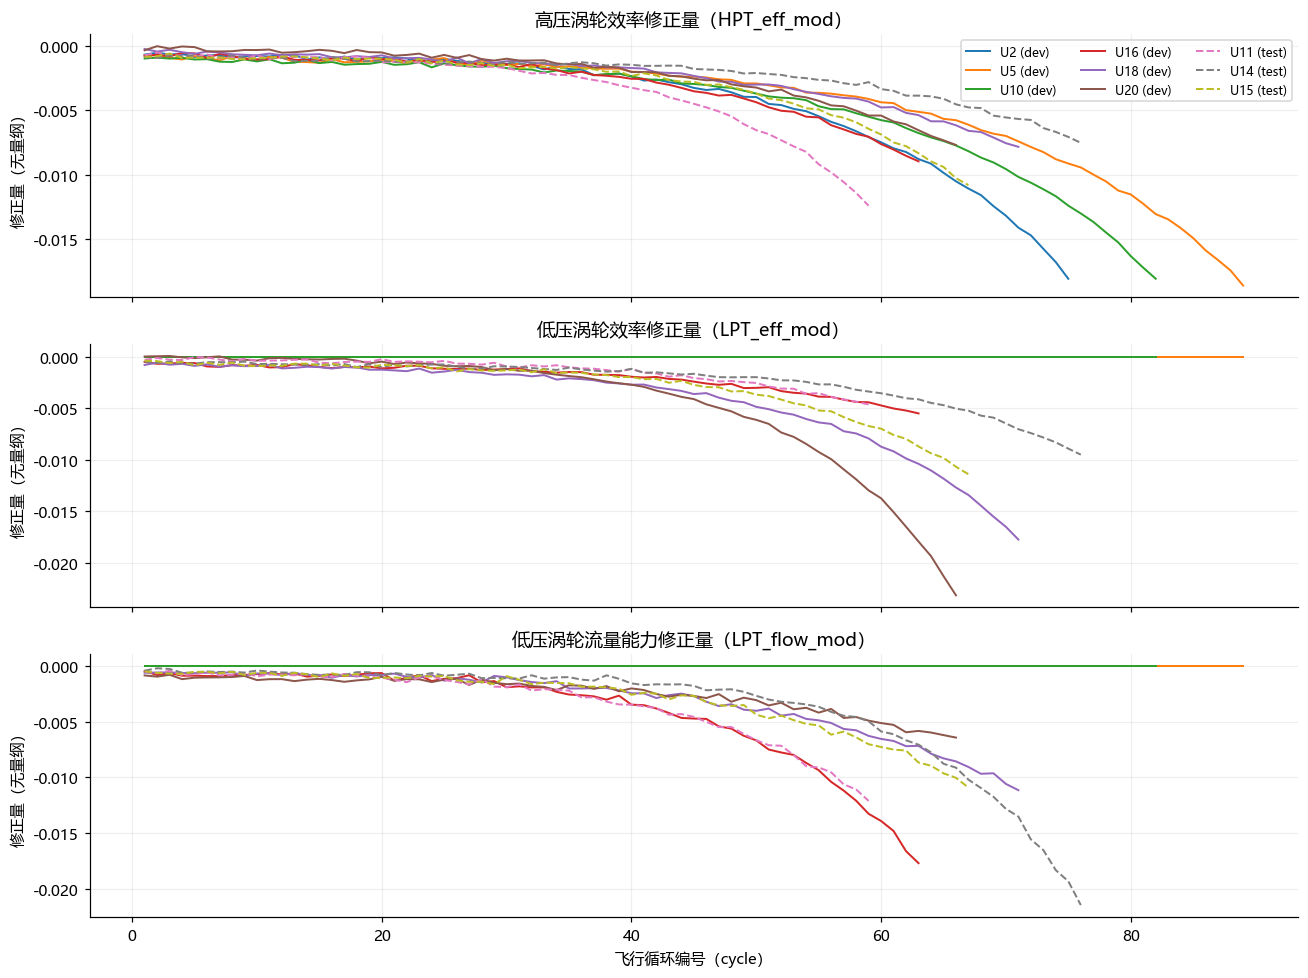

**读图：** 来源：当前 H5 所有发动机全量循环均值；开发集实线、测试集虚线。负值是修正量，不能直接标作“负健康度”。不同初始状态和退化组合需要不同的滤波先验支持。

**健康参数在单个循环内的最大范围（全量审计）：**

,max_within_cycle_range
HPT_eff_mod_within_range,0.0
LPT_eff_mod_within_range,0.0
LPT_flow_mod_within_range,0.0


In [9]:
train_cycle=cycles[(cycles.split=='dev') & cycles.unit.isin(TRAIN_UNITS)]
train_sp=samples[(samples.split=='dev') & samples.unit.isin(TRAIN_UNITS)]
# 通道筛选用每个训练循环的真实均值及循环内范围；不是拿测试集挑特征。
train_spans={n:float(train_cycle[n].max()-train_cycle[n].min()) for n in NAMES['T']}
active=[n for n,v in train_spans.items() if v>1e-6]
display(Markdown('**训练发动机中变化的健康通道：** '+', '.join(f'`{n}`' for n in active)))
display(ranges[ranges.group=='T'].reset_index(drop=True))
theta_unit=cycles.groupby(['split','unit'])[NAMES['T']].agg(lambda x:x.max()-x.min())
fig,ax=plt.subplots(figsize=(12,4.8))
im=ax.imshow(theta_unit.to_numpy(),aspect='auto',cmap='Blues')
ax.set(xticks=np.arange(len(NAMES['T'])),xticklabels=NAMES['T'],
       yticks=np.arange(len(theta_unit)),yticklabels=[f'{s} U{u}' for s,u in theta_unit.index],
       title='各发动机健康参数的跨循环范围（最大值 − 最小值）',xlabel='健康参数',ylabel='发动机')
plt.setp(ax.get_xticklabels(),rotation=40,ha='right')
fig.colorbar(im,ax=ax,label='参数变化范围（无量纲）'); fig.tight_layout()
show(fig,'06_health_activity','来源：全量循环均值。零范围表示该发动机该通道没有随循环变化，不表示发动机整体没有退化。')
fig,axs=plt.subplots(len(active),1,figsize=(12,3*len(active)),sharex=True,squeeze=False)
palette=plt.get_cmap('tab10')
for j,n in enumerate(active):
    ax=axs[j,0]
    for i,row in units.iterrows():
        g=cycles[(cycles.split==row.split)&(cycles.unit==row.unit)].sort_values('cycle')
        ax.plot(g.cycle,g[n],label=f'U{row.unit} ({row.split})',color=palette(i),
                ls='--' if row.split=='test' else '-',lw=1.3)
    ax.set(title=DESCRIPTIONS[n][0]+f'（{n}）',ylabel='修正量（无量纲）'); ax.grid(alpha=.2)
axs[0,0].legend(ncol=3,fontsize=8)
axs[-1,0].set_xlabel('飞行循环编号（cycle）'); fig.tight_layout()
show(fig,'07_health_trajectories','来源：当前 H5 所有发动机全量循环均值；开发集实线、测试集虚线。负值是修正量，不能直接标作“负健康度”。不同初始状态和退化组合需要不同的滤波先验支持。')
within=cycles[[n+'_within_range' for n in active]].max()
display(Markdown('**健康参数在单个循环内的最大范围（全量审计）：**'))
display(within.to_frame('max_within_cycle_range'))

## 8. `hs`、连续健康参数 θ、整体 HI、RUL 不能互相替代

- `hs` 是阶段标记；`T` 是各部件健康参数；`Y` 是剩余循环。
- [论文 §3.2] 整体 HI 来自参考工况下的性能裕度聚合，不能直接把当前飞行工况下的某个 `Sm*` 或 `T48` 线性归一化就称作原论文 HI。
- 原文寿命终止规则还包含运行循环数限制，不能不加检查就把每条轨迹末端都解释成真实灾难失效。

以下直接展示 `hs` 与健康参数的时间对应关系。图中同时变化只说明它们由共同退化机制生成，不构成独立因果验证。

,split,unit,hs_min,hs_max,mean_hs
0,dev,2,0.0,1.0,0.213333
1,dev,5,0.0,1.0,0.179775
2,dev,10,0.0,1.0,0.195122
3,dev,16,0.0,1.0,0.238095
4,dev,18,0.0,1.0,0.225352
5,dev,20,0.0,1.0,0.242424
6,test,11,0.0,1.0,0.305085
7,test,14,0.0,1.0,0.460526
8,test,15,0.0,1.0,0.343284


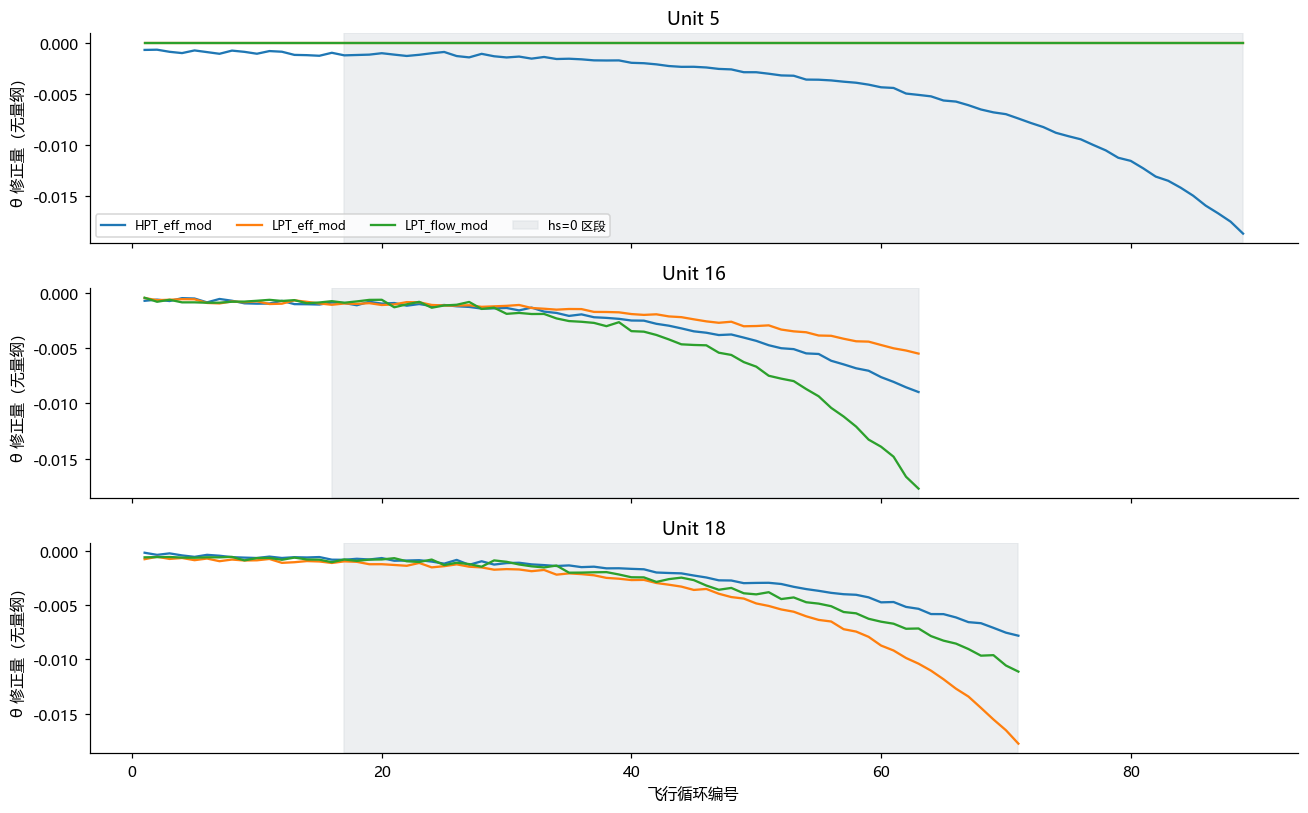

**读图：** 来源：三个开发集发动机的全量循环汇总。灰色区域按实际 hs 标记绘制；它不是可在无标签目标域直接读取的在线健康诊断结果。

In [10]:
hs_audit=cycles.groupby(['split','unit']).agg(hs_min=('hs','min'),hs_max=('hs','max'),
                                            mean_hs=('hs','mean')).reset_index()
display(hs_audit)
chosen=[5,16,18]
fig,axs=plt.subplots(len(chosen),1,figsize=(12,7.5),sharex=True)
for ax,u in zip(axs,chosen):
    g=cycles[(cycles.split=='dev') & (cycles.unit==u)].sort_values('cycle')
    for n in active: ax.plot(g.cycle,g[n],label=n)
    abnormal=g[g.hs<.5]
    if len(abnormal): ax.axvspan(abnormal.cycle.min(),g.cycle.max(),color='#D8DDE1',alpha=.45,label='hs=0 区段')
    ax.set(title=f'Unit {u}',ylabel='θ 修正量（无量纲）')
axs[0].legend(ncol=4,fontsize=8); axs[-1].set_xlabel('飞行循环编号'); fig.tight_layout()
show(fig,'08_hs_and_theta','来源：三个开发集发动机的全量循环汇总。灰色区域按实际 hs 标记绘制；它不是可在无标签目标域直接读取的在线健康诊断结果。')

## 9. 开发/测试工况差异：先看真实数据，再谈自适应

Fc 是飞行类别，不是故障编号，也不是上升/平飞/下降。下面比较每台发动机平均记录时长和阶段占比。

分布图中先给每台发动机归一化，再对同一 Fc 内的发动机等权平均，避免长寿命/长记录发动机垄断图形。每循环抽样点数一致，因此这里近似按循环等权，并非按秒加权。

原始论文 Fig. 3 展示了高度大于 10,000 ft 的记录片段；本文件全量高度下限也会在参数范围表中列出。因此 Fc=3 的记录片段平均只有约 3 小时，并不意味着原始完整航班应重新划为中程。不要按裁剪后的行数重新推导 Fc。

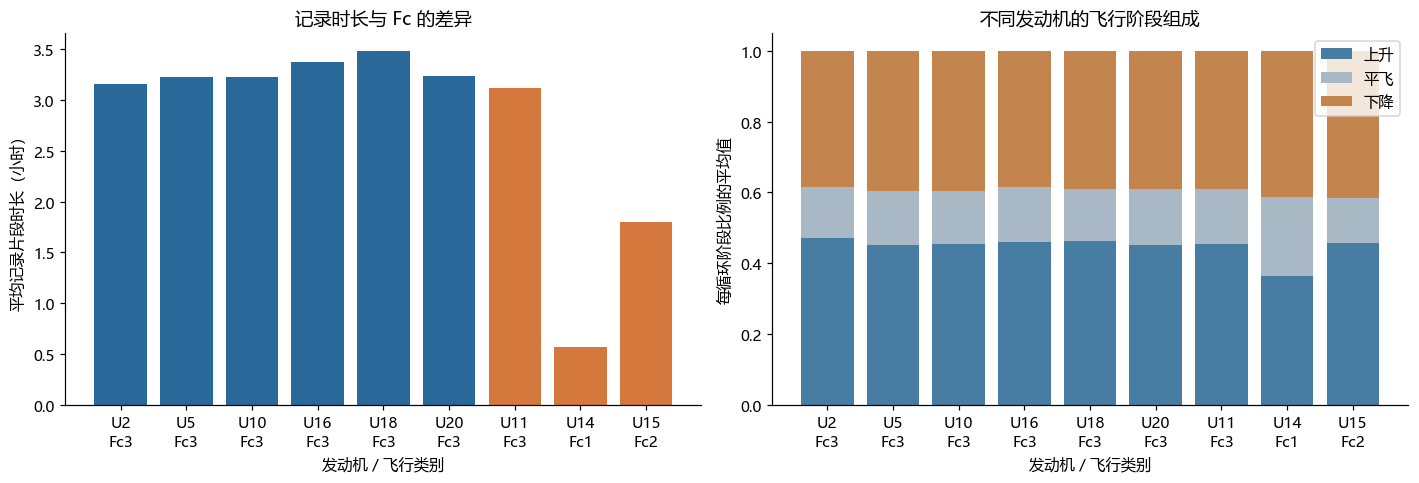

**读图：** 来源：全量循环统计。开发/测试的 Fc 差异与故障模式差异都可能影响泛化；不能把所有性能变化归因于工况。

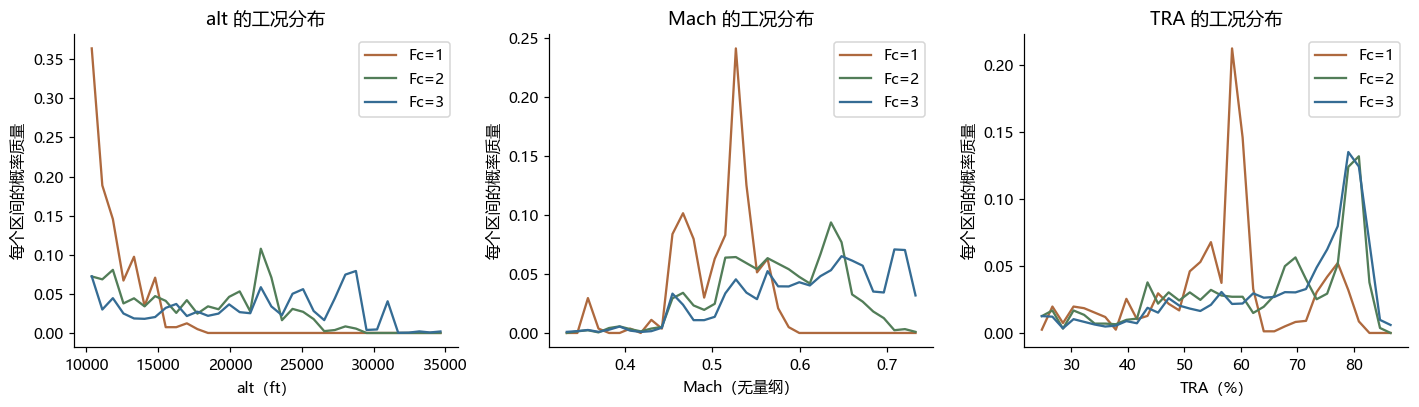

**读图：** 来源：每循环最多 32 点；每台发动机直方图归一化后按 Fc 等权平均。Fc=1/2 在 DS02 的独立发动机数量很少，不能把点数多当作总体代表性强。

In [11]:
fig,axs=plt.subplots(1,2,figsize=(13,4.5))
labels=[f'U{u}\nFc{fc}' for u,fc in zip(units.unit,units.Fc)]
axs[0].bar(labels,units.mean_recorded_hours,color=[COLORS[s] for s in units.split])
axs[0].set(ylabel='平均记录片段时长（小时）',xlabel='发动机 / 飞行类别',title='记录时长与 Fc 的差异')
phase_unit=cycles.groupby(['split','unit'])[[f'phase_{p}_fraction' for p in range(3)]].mean().reindex(list(zip(units.split,units.unit)))
bottom=np.zeros(len(units))
for p,label,col in [(0,'上升','#477CA3'),(1,'平飞','#A8B9C5'),(2,'下降','#C4844D')]:
    height=phase_unit[f'phase_{p}_fraction'].to_numpy()
    axs[1].bar(labels,height,bottom=bottom,label=label,color=col); bottom+=height
axs[1].set(ylabel='每循环阶段比例的平均值',xlabel='发动机 / 飞行类别',title='不同发动机的飞行阶段组成'); axs[1].legend()
fig.tight_layout()
show(fig,'09_operating_shift','来源：全量循环统计。开发/测试的 Fc 差异与故障模式差异都可能影响泛化；不能把所有性能变化归因于工况。')
fig,axs=plt.subplots(1,3,figsize=(13,3.8))
for ax,var in zip(axs,['alt','Mach','TRA']):
    lo,hi=samples[var].min(),samples[var].max(); edges=np.linspace(lo,hi,35)
    for fc,col in [(1,'#AE693E'),(2,'#527D58'),(3,'#356C94')]:
        d=samples[samples.Fc==fc]; hist=[]
        for _,g in d.groupby(['split','unit']):
            h,_=np.histogram(g[var],bins=edges); hist.append(h/h.sum())
        if hist: ax.plot((edges[:-1]+edges[1:])/2,np.mean(hist,axis=0),label=f'Fc={fc}',color=col)
    ax.set(title=f'{var} 的工况分布',xlabel=f'{var}（{DESCRIPTIONS[var][1]}）',ylabel='每个区间的概率质量'); ax.legend()
fig.tight_layout()
show(fig,'10_condition_distributions','来源：每循环最多 32 点；每台发动机直方图归一化后按 Fc 等权平均。Fc=1/2 在 DS02 的独立发动机数量很少，不能把点数多当作总体代表性强。')

## 10. 为校准铺垫：先观察“工况—传感器—健康参数”的混合关系

前向校准模型要描述 (F(W,\theta)\to X_s)，反向任务才是给定 (W,X_s\) 求健康参数后验。

先做一个**诊断性演示**：在训练发动机 `hs=1` 片段上拟合低阶工况回归 (g(W))，在验证发动机 Unit20 上观察残差 (X_s-g(W))。使用二次特征和固定岭正则；它不是发动机热力学模型，也不是粒子滤波。

**为何使用 hs 必须注明？** 因为这是仿真健康状态监督。此例只在训练数据选择基准样本，验证时不用 hs 选择输入。参数均只从训练数据估计，不使用测试集拟合。

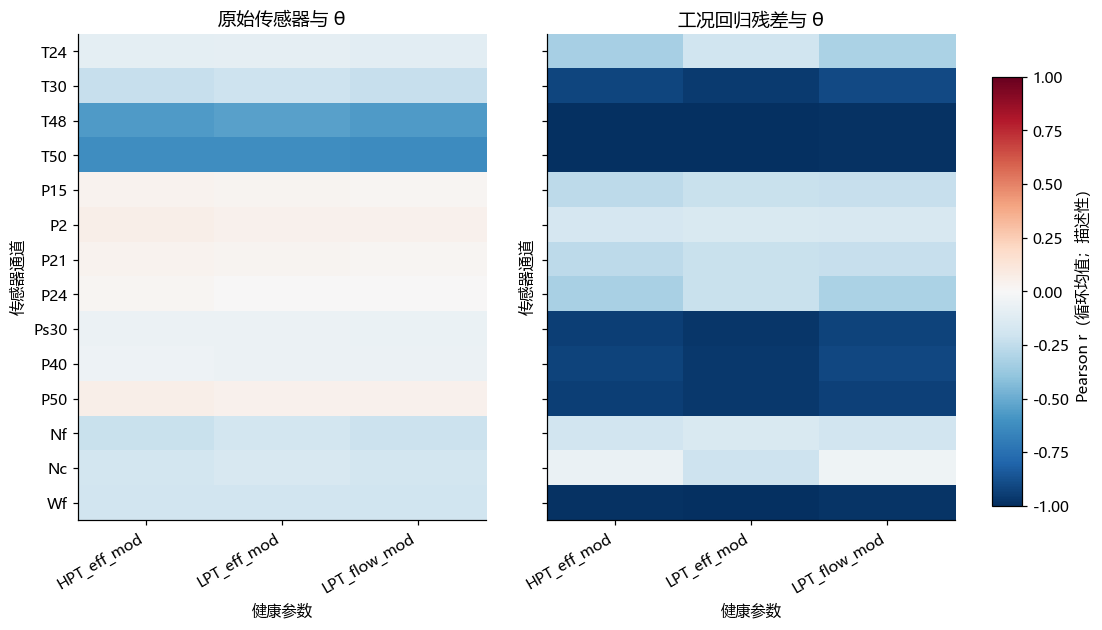

**读图：** 来源：Unit20 验证集的抽样循环均值；工况回归仅拟合训练发动机 hs=1 片段。相关性增强/减弱均需如实解释；共同随时间变化、故障共线性和工况外推都可能造成相关，不能据此宣称已反演出健康参数。

,sensor,raw_r_HPT,residual_r_HPT
0,T24,-0.099,-0.329
1,T30,-0.228,-0.919
2,T48,-0.570,-0.996
3,T50,-0.622,-0.993
4,P15,0.038,-0.260
5,P2,0.061,-0.170
6,P21,0.038,-0.260
7,P24,0.017,-0.327
8,Ps30,-0.055,-0.938
9,P40,-0.050,-0.925


In [12]:
# 工况回归仅用于诊断；不挑选最佳传感器、不做后续模型调参。
train_mask=(samples.split=='dev') & samples.unit.isin(TRAIN_UNITS) & (samples.hs==1)
valid_mask=(samples.split=='dev') & (samples.unit==VAL_UNIT)
tr=samples.loc[train_mask].copy(); va=samples.loc[valid_mask].copy()
assert len(tr)>50 and len(va)>20
wmean=tr[NAMES['W']].mean().to_numpy(); wstd=tr[NAMES['W']].std().to_numpy()
wstd=np.maximum(wstd,1e-8)
def design(w):
    z=(np.asarray(w)-wmean)/wstd
    return np.column_stack([np.ones(len(z)),z,z*z]+[z[:,i]*z[:,j] for i in range(4) for j in range(i+1,4)])
a=design(tr[NAMES['W']]); b=design(va[NAMES['W']])
penalty=np.eye(a.shape[1])*1e-3; penalty[0,0]=0
coef=np.linalg.solve(a.T@a+penalty,a.T@tr[NAMES['X_s']].to_numpy())
residual=va[NAMES['X_s']].to_numpy()-b@coef
for j,n in enumerate(NAMES['X_s']): va[n+'_residual']=residual[:,j]
# 汇总到循环，降低把相邻秒级样本当作独立证据的问题；不报告显著性。
vc=va.groupby('cycle').mean(numeric_only=True)
corr_raw=np.array([[vc[s].corr(vc[t]) for t in active] for s in NAMES['X_s']])
corr_res=np.array([[vc[s+'_residual'].corr(vc[t]) for t in active] for s in NAMES['X_s']])
fig,axs=plt.subplots(1,2,figsize=(11,6.5),sharey=True)
for ax,arr,title in zip(axs,[corr_raw,corr_res],['原始传感器与 θ','工况回归残差与 θ']):
    im=ax.imshow(arr,aspect='auto',vmin=-1,vmax=1,cmap='RdBu_r')
    ax.set(xticks=np.arange(len(active)),xticklabels=active,
           yticks=np.arange(len(NAMES['X_s'])),yticklabels=NAMES['X_s'],title=title,
           xlabel='健康参数',ylabel='传感器通道')
    plt.setp(ax.get_xticklabels(),rotation=30,ha='right')
fig.subplots_adjust(bottom=.2,right=.85,wspace=.15)
cax=fig.add_axes([.88,.22,.025,.6]); fig.colorbar(im,cax=cax,label='Pearson r（循环均值；描述性）')
show(fig,'11_condition_residual_diagnostic','来源：Unit20 验证集的抽样循环均值；工况回归仅拟合训练发动机 hs=1 片段。相关性增强/减弱均需如实解释；共同随时间变化、故障共线性和工况外推都可能造成相关，不能据此宣称已反演出健康参数。')
diagnostic=pd.DataFrame({'sensor':NAMES['X_s'],'raw_r_HPT':corr_raw[:,active.index('HPT_eff_mod')],
                         'residual_r_HPT':corr_res[:,active.index('HPT_eff_mod')]})
display(diagnostic.round(3))
diagnostic.to_csv(ARTIFACT_DIR/'condition_residual_diagnostic.csv',index=False,encoding='utf-8-sig')

## 11. 反演前的可辨识性检查：传感器多，不代表 θ 一定能唯一恢复

若两个健康参数在训练样本中总是同步变化，代理模型可能学不到“只改变其中一个”的响应。滤波器即使输出很窄的区间，也可能只是先验/噪声假设过强。

以下相关矩阵只检查训练数据中健康参数的共同变化；不是完整的结构可辨识性证明。后续应检查 (\partial F/\partial\theta) 的秩/条件数、参数后验相关性，以及仿真真值恢复误差。

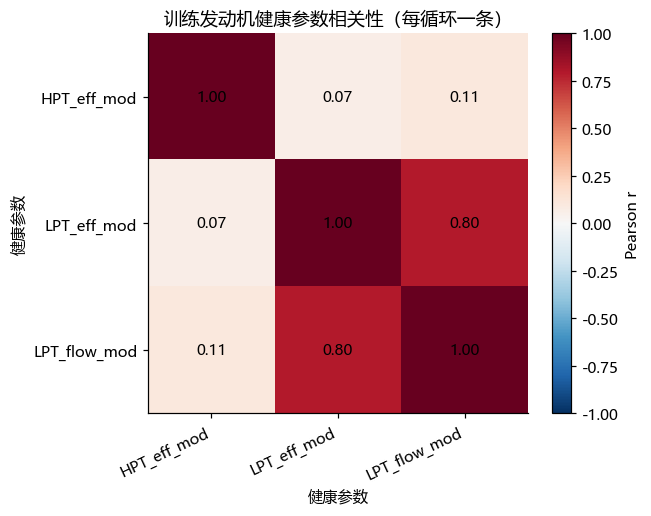

**读图：** 来源：训练发动机的全量循环均值。高相关提示需要小心区分部件贡献；不能靠增加粒子数解决所有信息不足问题。

In [13]:
theta_corr=train_cycle[active].corr()
fig,ax=plt.subplots(figsize=(6,4.8))
im=ax.imshow(theta_corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set(xticks=range(len(active)),xticklabels=active,yticks=range(len(active)),yticklabels=active,
       title='训练发动机健康参数相关性（每循环一条）',xlabel='健康参数',ylabel='健康参数')
plt.setp(ax.get_xticklabels(),rotation=25,ha='right')
for i in range(len(active)):
    for j in range(len(active)): ax.text(j,i,f'{theta_corr.iloc[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im,ax=ax,label='Pearson r'); fig.tight_layout()
show(fig,'12_parameter_identifiability','来源：训练发动机的全量循环均值。高相关提示需要小心区分部件贡献；不能靠增加粒子数解决所有信息不足问题。')

## 12. 参数关系的一个实例：观测通道并不一定提供独立信息

下面用 P15 与 P21 检查一个可直接从本文件验证的关系。全量扫描统计比值范围，散点仅用于展示。若两个通道近似固定比例，将它们都当作独立高斯观测相乘，会重复计入证据，使后验可能过度集中。

这是**当前 DS02 文件的经验关系**，不是未经推导即可用于所有发动机的物理定律。它说明校准前需要检查观测冗余和残差协方差。

全量比值范围：`P15/P21 ∈ [0.985000000000, 0.985000000000]`。

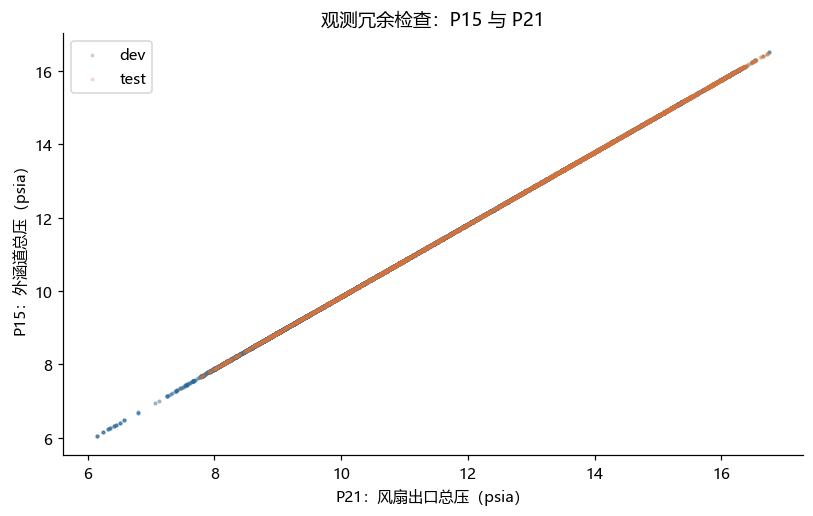

**读图：** 来源：每循环最多32点散点；比值上下限来自全量原始行。重复信息不增加可辨识维度，后续应比较去冗余或含残差协方差的观测似然。

In [14]:
ratio_lo=float(cycles.P15_P21_ratio_min.min()); ratio_hi=float(cycles.P15_P21_ratio_max.max())
display(Markdown(f'全量比值范围：`P15/P21 ∈ [{ratio_lo:.12f}, {ratio_hi:.12f}]`。'))
fig,ax=plt.subplots(figsize=(7.5,4.8))
for split in ['dev','test']:
    g=samples[samples.split==split]
    ax.scatter(g.P21,g.P15,s=3,alpha=.2,label=split,color=COLORS[split],rasterized=True)
ax.set(xlabel='P21：风扇出口总压（psia）',ylabel='P15：外涵道总压（psia）',
       title='观测冗余检查：P15 与 P21'); ax.legend(); fig.tight_layout()
show(fig,'13_sensor_redundancy','来源：每循环最多32点散点；比值上下限来自全量原始行。重复信息不增加可辨识维度，后续应比较去冗余或含残差协方差的观测似然。')

## 13. 后续粒子滤波需要什么？这份数据分析提供了什么？

**状态**：筛出的健康参数向量 \(\theta_c\)。尺度按实际修正量设置，不固定裁剪到 `[0,1]`。

**状态转移**：\(p(\theta_c\mid\theta_{c-1})\)。从训练发动机估计初始状态分布、跨循环漂移和过程噪声；正常/异常阶段可能不同。不要从目标真实 θ 中读取初值。

**观测模型**：\(p(X_s\mid W,\theta)\)。优先使用可调用的性能仿真器；若只能用神经代理模型，应称为“代理模型辅助校准”，记录额外 θ 监督与代理模型误差。

**顺序更新**：\(p(\theta_{\le t}\mid W_{\le t},X_{s,\le t})\)。同循环中可以累计多次观测；不能用循环末端数据更新后再回填早期窗口。

**评估分两层**：① θ 的 RMSE/MAE、后验覆盖、有效粒子数与边界占比；②相同 Transformer、相同划分下比较 `W+Xs`、`W+Xs+估计θ`、`W+Xs+真实θ`。真实 θ 是 **oracle 特权信息参考**，不是有限模型必然达到的数学性能上限。

**与两篇自适应论文的连接**：

1. 用同发动机、不同循环的样本对学习 RUL 差值，时间单位保持 cycle；原 SSDA 论文主实验是 C-MAPSS，迁移到本文件需要上述标签检查。
2. 对上升/平飞/下降分别对齐；原工况对齐论文使用 N-CMAPSS DS03，多发动机跨域协议与当前 DS02 不同，不能直接比较论文分数。
3. DS02 的 Fc=1/2 独立发动机很少，先明确“同目标发动机前缀适应、后缀评估”与“独立目标发动机测试”的区别。

**最小对照**：基线 → 校准 → 校准+时序 → 校准+工况对齐 → 两者融合；另列 oracle。每个实验必须使用相同测试样本、训练预算和固定种子组。

## 14. 自动生成组会结论与质量检查

下面的数字来自本次执行，不手工填写成绩。若更换 H5 文件，结论中的计数和参数列表也会重新计算。这里仅做数据分析，**没有**训练或验证粒子滤波/RUL 模型的预测效果。

In [15]:
nonfinite=int(ranges.nonfinite.sum()+cycles.A_missing.sum()+cycles.Y_missing.sum())
fc_mapping={str(int(r.unit)):int(r.Fc) for _,r in units.iterrows()}
constant=[n for n in NAMES['T'] if n not in active]
summary={
 'dataset':DATA_PATH.name,'bytes':DATA_PATH.stat().st_size,'rows':row_counts,
 'total_cycles':len(cycles),'engines':len(units),'nonfinite_numeric_values':nonfinite,
 'train_units':TRAIN_UNITS,'validation_unit':VAL_UNIT,
 'test_units':units.loc[units.split=='test','unit'].astype(int).tolist(),
 'flight_class_by_unit':fc_mapping,'active_train_health_parameters':active,
 'constant_train_health_parameters':constant,
 'max_RUL_range_within_cycle':float(label_audit.max_RUL_range_in_cycle.max()),
 'max_range_RUL_plus_cycle':float(label_audit.range_RUL_plus_cycle.max()),
 'max_theta_within_cycle_range':{n:float(cycles[n+'_within_range'].max()) for n in active},
 'sampled_points_for_scatter':len(samples),
 'P15_P21_ratio_full_data':[ratio_lo,ratio_hi],
 'notes':'EDA only; no PF/RUL training; test data are descriptive, not used in regression fitting',
 'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'h5py':h5py.__version__,'matplotlib':matplotlib.__version__}
}
(ARTIFACT_DIR/'analysis_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
test_fc=', '.join(f'Unit {int(r.unit)} → Fc={int(r.Fc)}' for _,r in units[units.split=='test'].iterrows())
display(Markdown(f"""
### 本次文件的实测结论

1. **{len(units)} 台发动机**，开发集 **{row_counts['dev']:,} 行**、测试集 **{row_counts['test']:,} 行**，共 **{len(cycles)} 个飞行循环**。海量行数不等于海量独立发动机。
2. 测试发动机类别：**{test_fc}**；开发集 Fc 实际取值为 **{sorted(units[units.split=='dev'].Fc.unique().tolist())}**。
3. 训练发动机中变化的 θ 是 **{', '.join(active)}**；其他通道在本训练设置中基本不变。
4. 同一循环内 RUL 最大变化范围为 **{summary['max_RUL_range_within_cycle']:.3g}**；同一发动机 `Y+cycle` 最大范围为 **{summary['max_range_RUL_plus_cycle']:.3g}**。这两项决定时序自监督公式能否成立。
5. 数值组 W/Xs/Xv/T/A/Y 的非有限值总数为 **{nonfinite}**。非有限值为零不等于没有噪声或分布偏移。
6. 已建立原始信号、真实健康轨迹和工况之间的检查框架；**校准有潜力，但是否改善预测仍需统一协议下的对照实验**。

### 可直接用于组会的表述

“本周先完成 DS02-006 的数据审计。明确了输入工况与仿真响应的区别，确认了标签以飞行循环计数，并识别了训练数据中实际变化的健康参数。下一步将以这些参数作为待估计状态，建立前向观测模型与顺序滤波器，先检查健康参数恢复质量，再比较对 Transformer RUL 预测的影响。”
"""))
assert nonfinite==0, '发现缺失或无穷值，应先处理再开展校准'
assert summary['max_RUL_range_within_cycle'] < 1e-6
assert summary['max_range_RUL_plus_cycle'] < 1e-6
print('PASS：行对齐、循环块唯一、统计覆盖所有行、无非有限值、循环级标签关系。')
print('图表/字典/汇总已保存到：',ARTIFACT_DIR.resolve())


### 本次文件的实测结论

1. **9 台发动机**，开发集 **5,263,447 行**、测试集 **1,253,743 行**，共 **648 个飞行循环**。海量行数不等于海量独立发动机。
2. 测试发动机类别：**Unit 11 → Fc=3, Unit 14 → Fc=1, Unit 15 → Fc=2**；开发集 Fc 实际取值为 **[3]**。
3. 训练发动机中变化的 θ 是 **HPT_eff_mod, LPT_eff_mod, LPT_flow_mod**；其他通道在本训练设置中基本不变。
4. 同一循环内 RUL 最大变化范围为 **0**；同一发动机 `Y+cycle` 最大范围为 **0**。这两项决定时序自监督公式能否成立。
5. 数值组 W/Xs/Xv/T/A/Y 的非有限值总数为 **0**。非有限值为零不等于没有噪声或分布偏移。
6. 已建立原始信号、真实健康轨迹和工况之间的检查框架；**校准有潜力，但是否改善预测仍需统一协议下的对照实验**。

### 可直接用于组会的表述

“本周先完成 DS02-006 的数据审计。明确了输入工况与仿真响应的区别，确认了标签以飞行循环计数，并识别了训练数据中实际变化的健康参数。下一步将以这些参数作为待估计状态，建立前向观测模型与顺序滤波器，先检查健康参数恢复质量，再比较对 Transformer RUL 预测的影响。”


PASS：行对齐、循环块唯一、统计覆盖所有行、无非有限值、循环级标签关系。
图表/字典/汇总已保存到： C:\Users\Alina\Documents\Codex\2026-09-27\xie\outputs\DS02_analysis_assets


## 参考与复现说明

1. Arias Chao et al. (2021). 数据集生成、变量定义、退化与噪声机制。[原始论文](https://doi.org/10.3390/data6010005)。变量表按其定义整理；具体尺寸、数值范围和图形均由本地 H5 计算。
2. Le Xuan et al. (2024). 时序差值自监督，重点 Eq. 23–25。[论文](https://doi.org/10.1016/j.ress.2024.110296)。
3. Nejjar et al. (2024). 飞行阶段内域对齐，重点 Fig. 3–4 和 §4 的阶段定义。[论文](https://doi.org/10.1016/j.ress.2023.109718)。

环境：Python、numpy、pandas、h5py、matplotlib、IPython；执行 notebook 另需 ipykernel。原数据不会随 notebook 打包。修改第 0 节的 DATA_PATH 即可重跑。执行输出已嵌入此文件；导出的 PNG/CSV 是便于汇报的副本。

**分析边界**：变量范围/逐循环均值为全量统计；散点与相关性使用固定的每循环抽样。我们已查看测试集描述统计，因此后续应冻结实验协议，不根据测试图反复选择超参数。本文不提供真实发动机部署效果保证，也不声称已完成物理模型校准。